# Encoder-Decoder Transformer: Positional Encodings on Two Tasks
Full architecture from *Attention Is All You Need* (encoder, decoder, cross-attention), trained on **Tiny Shakespeare** (character level).

Four position schemes x two tasks = 8 models, **default hyperparameters, no tuning**, identical seed and data for every run:

| Encoding | Idea |
|---|---|
| `sinusoidal` | static sin/cos added to embeddings |
| `learned` | trainable vector per position |
| `rope` | rotary embedding on Q/K (self-attention only) |
| `none` | no position information (baseline) |

| Task | Source -> Target |
|---|---|
| `reverse` | 64 characters -> the same 64 characters reversed |
| `continuation` | 64 characters -> the next 64 characters of the text |

The notebook shows **generated text from every encoding on the same fixed validation examples**, so the differences can be read directly.

**Colab:** Runtime -> Change runtime type -> T4 GPU, then Runtime -> Run all. Set `QUICK = True` in section 1 for a 300-step smoke test first.

## 0. Setup
Clones the GitHub repo if `transformer_encdec.py` is not in the working folder.

In [1]:
import os
REPO_URL = "https://github.com/Aryam-21/Transformer-architecture-and-self-attention.git"
REPO_DIR = "Transformer-architecture-and-self-attention"

if not os.path.exists("transformer_encdec.py"):
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    %cd {REPO_DIR}
    !git pull
!ls

Cloning into 'Transformer-architecture-and-self-attention'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 19 (delta 6), reused 15 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 18.18 KiB | 6.06 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/Transformer-architecture-and-self-attention
Already up to date.
README.md  requirements.txt  transformer_encdec.py  transformer_lib.py


In [2]:
import math, time
from dataclasses import replace
import torch, pandas as pd, matplotlib.pyplot as plt
from transformer_encdec import (Config, POS_TYPES, TASKS, EncoderDecoderTransformer, load_data, train,
                                evaluate_at_length, generate_eval, decode_text, sequence_metrics,
                                per_position_accuracy, continue_text, save_results)
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


## 1. Configuration (defaults, no tuning)
Model size and optimiser settings are the library defaults. Only the number of training steps differs per task:
- `reverse` is learned quickly (3 of 4 encodings are near-perfect within ~500 steps), so 2500 steps is enough for the slowest one.
- `continuation` is a harder, open-ended task, so it gets 4000 steps (about 25 passes over the text's characters; the table below reports both the final and the best validation loss in case it starts to overfit).

In [3]:
QUICK = False                     # True = 300 steps per run, just to check everything works
ITERS = {"reverse": 2500, "continuation": 4000}
if QUICK:
    ITERS = {t: 300 for t in TASKS}

base = Config()                   # library defaults: d_model=256, 4 heads, 3+3 layers, src_len=tgt_len=64
cfgs = {t: replace(base, task=t, max_iters=ITERS[t], eval_interval=max(ITERS[t] // 12, 25)) for t in TASKS}
for t, c in cfgs.items():
    seen = c.max_iters * c.batch_size * (c.src_len + c.tgt_len) / 1e6
    print(f"{t:13s} steps={c.max_iters} batch={c.batch_size} -> ~{seen:.0f}M characters processed")

reverse       steps=2500 batch=64 -> ~20M characters processed
continuation  steps=4000 batch=64 -> ~33M characters processed


## 2. Load data

In [4]:
train_data, val_data, chars, stoi, itos = load_data()
vocab_size = len(chars)
print(f"vocab size: {vocab_size} (+1 BOS) | train chars: {len(train_data):,} | val chars: {len(val_data):,}")

vocab size: 65 (+1 BOS) | train chars: 1,003,854 | val chars: 111,540


## 3. Train all 8 models (2 tasks x 4 encodings)
This is the long cell. Checkpoints are saved to `checkpoints/`.

In [5]:
os.makedirs("checkpoints", exist_ok=True)
results = {t: {} for t in TASKS}
t_start = time.time()
for task in TASKS:
    for pos in POS_TYPES:
        results[task][pos] = train(pos, cfgs[task], train_data, val_data, vocab_size, itos)
        torch.save(results[task][pos]["model"].state_dict(), f"checkpoints/{task}_{pos}.pt")
    save_results(results[task], f"results_{task}.json")
print(f"\nTotal training time: {(time.time() - t_start) / 60:.1f} min")


=== reverse | sinusoidal | 5.54M params | 2500 steps | device=cuda ===
step     0 | train 4.2711 | val 4.2672 | val tok-acc 0.026
step   208 | train 0.1781 | val 0.2012 | val tok-acc 0.960
step   416 | train 0.0034 | val 0.0033 | val tok-acc 1.000
step   624 | train 0.0041 | val 0.0043 | val tok-acc 0.999
step   832 | train 0.0006 | val 0.0007 | val tok-acc 1.000
step  1040 | train 0.0007 | val 0.0008 | val tok-acc 1.000
step  1248 | train 0.0003 | val 0.0003 | val tok-acc 1.000
step  1456 | train 0.0002 | val 0.0002 | val tok-acc 1.000
step  1664 | train 0.0001 | val 0.0001 | val tok-acc 1.000
step  1872 | train 0.0001 | val 0.0001 | val tok-acc 1.000
step  2080 | train 0.0000 | val 0.0000 | val tok-acc 1.000
step  2288 | train 0.0000 | val 0.0000 | val tok-acc 1.000
step  2496 | train 0.0000 | val 0.0000 | val tok-acc 1.000
step  2500 | train 0.0000 | val 0.0000 | val tok-acc 1.000
greedy decoding: char acc 1.000 | exact match 1.000

=== reverse | learned | 5.67M params | 2500 steps

## 4. Learning curves

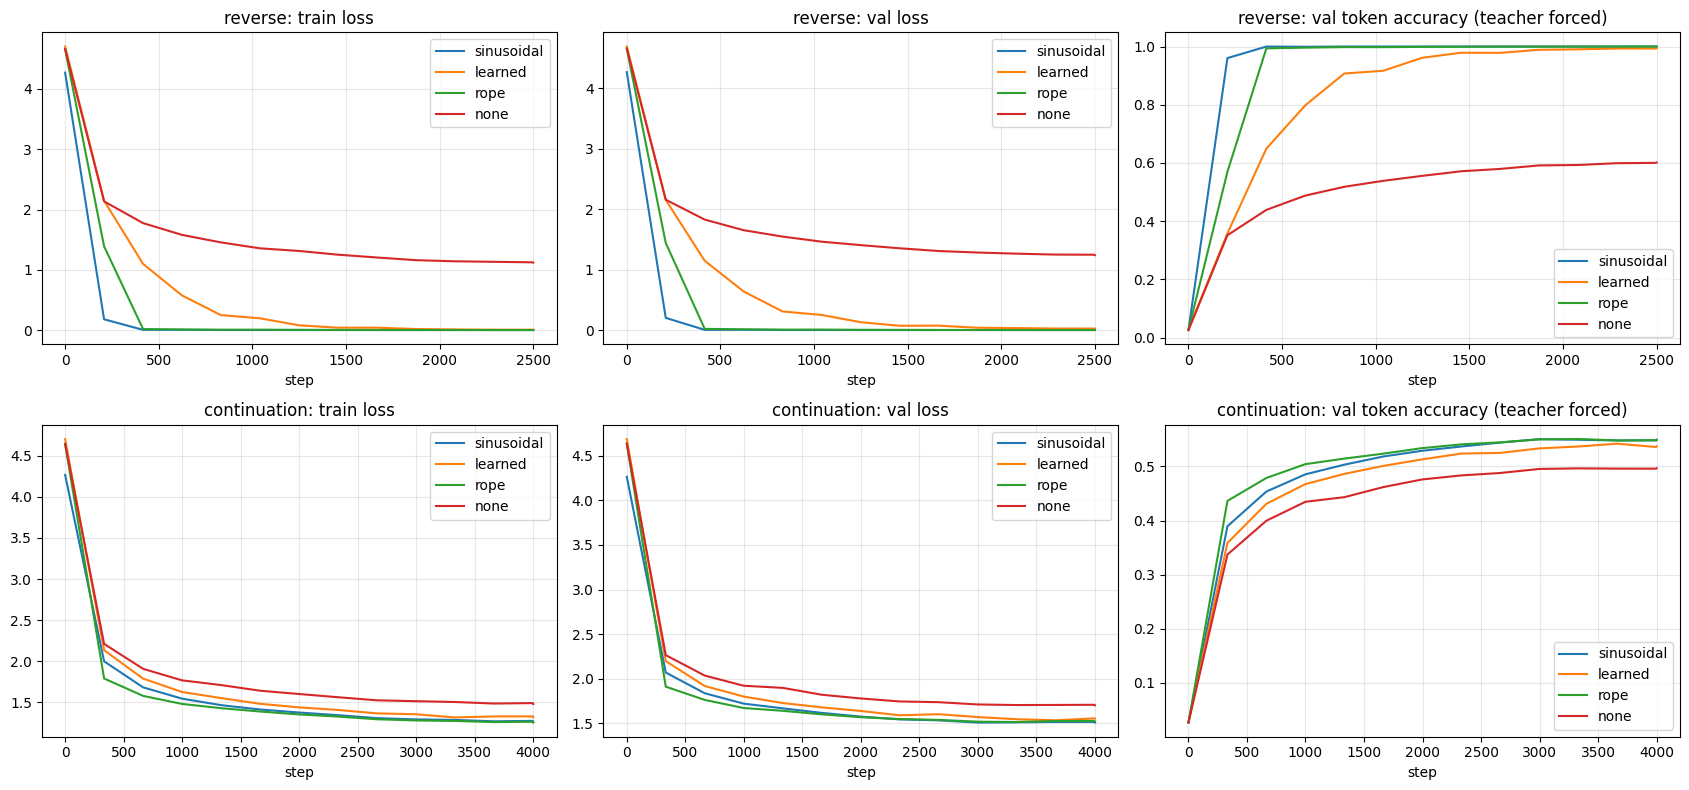

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for row, task in enumerate(TASKS):
    for pos, r in results[task].items():
        h = r["history"]
        axes[row, 0].plot(h["step"], h["train_loss"], label=pos)
        axes[row, 1].plot(h["step"], h["val_loss"], label=pos)
        axes[row, 2].plot(h["step"], h["val_acc"], label=pos)
    for ax, t in zip(axes[row], ["train loss", "val loss", "val token accuracy (teacher forced)"]):
        ax.set_title(f"{task}: {t}"); ax.set_xlabel("step"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("curves.png", dpi=150); plt.show()

## 5. Summary tables
- **val loss / token acc**: teacher forced (the decoder sees the true previous characters).
- **greedy char acc / exact match**: free-running generation on 512 *fixed* validation examples (the same for every model). This is the realistic test.

In [7]:
def summary_table(task):
    rows = []
    for pos, r in results[task].items():
        h, g = r["history"], r["greedy"]
        rows.append({
            "encoding": pos,
            "final val loss": h["val_loss"][-1],
            "best val loss": min(h["val_loss"]),
            "val perplexity": math.exp(h["val_loss"][-1]),
            "val token acc": h["val_acc"][-1],
            "greedy char acc": g["char_acc"],
            "exact match": g["exact_match"],
            "ms / step": r["sec_per_step"] * 1000,
        })
    return pd.DataFrame(rows).set_index("encoding").round(4)

for task in TASKS:
    print(f"\n=== {task} ===")
    display(summary_table(task))


=== reverse ===


,final val loss,best val loss,val perplexity,val token acc,greedy char acc,exact match,ms / step
encoding,,,,,,,
sinusoidal,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,61.2163
learned,0.0228,0.0228,1.0231,0.9935,0.9313,0.7656,61.1107
rope,0.0005,0.0004,1.0005,0.9998,0.9911,0.9844,65.8130
none,1.2391,1.2391,3.4525,0.6016,0.0717,0.0000,60.8268



=== continuation ===


,final val loss,best val loss,val perplexity,val token acc,greedy char acc,exact match,ms / step
encoding,,,,,,,
sinusoidal,1.5095,1.5089,4.5245,0.5494,0.0794,0.0,60.5316
learned,1.5538,1.5345,4.7296,0.5372,0.0762,0.0,60.6040
rope,1.5207,1.5148,4.5752,0.5487,0.0686,0.0,65.5950
none,1.7019,1.7019,5.4845,0.4965,0.0732,0.0,60.3845


On the reverse task, all three positional encodings solve the problem and the no-position baseline fails (0% exact match), though teacher-forced accuracy hides this (60%). Sinusoidal reaches 100% exact match, RoPE 98.4%, and learned 76.6% after 2500 steps and is still improving. On continuation, the differences are much smaller: sinusoidal and RoPE are tied (perplexity about 4.5), learned is slightly behind (4.73), and no-position is worst (5.48). This is a single-seed result, so small gaps should not be over-interpreted

## 6. Generated text: REVERSE task
Same 4 validation examples for every encoding. Under each prediction, a `^` marks every character that differs from the target. The percentage is the character accuracy of that prediction. (`¶` = newline.)

In [8]:
def show_generation(task, n_show=4, seed=0, temperature=0.0):
    cfg = cfgs[task]
    outs = {}
    for pos, r in results[task].items():
        src, tgt, pred = generate_eval(r["model"], val_data, cfg, n=n_show, seed=seed, temperature=temperature)
        outs[pos] = pred
    for k in range(n_show):
        print("=" * 80)
        print(f"{'SOURCE':11s}: {decode_text(src[k], itos)}")
        print(f"{'TARGET':11s}: {decode_text(tgt[k], itos)}")
        for pos, pred in outs.items():
            p = pred[k]
            acc = (p == tgt[k]).float().mean().item()
            print(f"{pos:11s}: {decode_text(p, itos)}   [{acc:.0%}]")
            print(" " * 13 + "".join(" " if a == b else "^" for a, b in zip(p.tolist(), tgt[k].tolist())))

show_generation("reverse", n_show=4)

SOURCE     : ooked for:¶I am your neighbour, and was suitor first.¶¶TRANIO:¶A
TARGET     : A¶:OINART¶¶.tsrif rotius saw dna ,ruobhgien ruoy ma I¶:rof dekoo
sinusoidal : A¶:OINART¶¶.tsrif rotius saw dna ,ruobhgien ruoy ma I¶:rof dekoo   [100%]
                                                                             
learned    : A¶:OINART¶¶.tsrif rotius saw dna ,ruobhgien ruoy ma I¶:rof dekoo   [100%]
                                                                             
rope       : A¶:OINART¶¶.tsrif rotius saw dna ,ruobhgien ruoy ma I¶:rof dekoo   [100%]
                                                                             
none       : on ,ris ruoy fI¶:ANOIRT¶¶.suoitarg ruo dna ekam siht worb doofer   [3%]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^ ^^^^^^^^^^^^^^^^^^^^^^^ ^^^^^^^^
SOURCE     : hy, and of worthy birth;¶Beside, so qualified as may beseem¶The 
TARGET     :  ehT¶meeseb yam sa deifilauq os ,ediseB¶;htrib yhtrow fo dna ,yh
sinusoidal :  ehT¶meeseb yam s

## 7. Generated text: CONTINUATION task (greedy)
The encoder reads the 64-character source; the decoder writes the next 64 characters. Greedy decoding is deterministic, so differences come from the model, not from sampling. `^` marks characters that differ from the *true* continuation (a good continuation can still differ from the true one, so low accuracy here is normal).

In [9]:
show_generation("continuation", n_show=4)

SOURCE     : ooked for:¶I am your neighbour, and was suitor first.¶¶TRANIO:¶A
TARGET     : nd I am one that love Bianca more¶Than words can witness, or you
sinusoidal : nd then the world of the season of the sea¶To see the season of    [19%]
                ^^^^ ^^  ^^^^^^ ^^^^^^^^ ^^^^^^^^^^ ^^^^^^^^^^^^^^^ ^^^ ^ ^^^
learned    : nd the shall be so so so more to the prove¶That the prove of the   [11%]
                ^^^^^^^^^^^^^^^^^^ ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^  ^ ^^^
rope       : nd the common the world of the country's son,¶And shall be so st   [8%]
                ^^^^^ ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^ ^^^^^^^^^^^^^^^^
none       :  the shall be the shall be the see the shall be¶The shall be the   [9%]
             ^^^^ ^^^^^^^^^^^^^^^^^^^^^^^^^^^ ^^^^^ ^^^^^ ^^^^^^^^^^^^ ^^ ^^^
SOURCE     : hy, and of worthy birth;¶Beside, so qualified as may beseem¶The 
TARGET     : spouse of any noble gentleman.¶Let me embrace with old Vincentio
sinusoidal : shall be so be so so 

## 8. Longer generated Shakespeare (CONTINUATION task)
Starting from one 64-character prompt, each model writes 4 chunks of 64 characters (256 characters in total). Each generated chunk is fed back as part of the next source. Sampling uses temperature 0.8 with the same random seed for every model.

In [10]:
cfg = cfgs["continuation"]
prompt = val_data[2000 : 2000 + cfg.src_len]
print("PROMPT:", decode_text(prompt, itos, keep_newlines=True).replace("\n", " / "))
print("=" * 80)
for pos, r in results["continuation"].items():
    torch.manual_seed(0)
    out = continue_text(r["model"], prompt, cfg, n_chunks=4, temperature=0.8)
    print(f"--- {pos} ---")
    print(decode_text(out, itos, keep_newlines=True))
    print()

PROMPT: ept his service. /  / BAPTISTA: / A thousand thanks, Signior Gremio. / W
--- sinusoidal ---
hy shall heaven their counsel, my lord.

Nurse:
And we have my him controcken himself:
He is gold lords with me shear but the to live,
And if a garlish'd but bawd the state to drum
That but be in seven of thee own formires;
And less he is like alone: he is

--- learned ---
hy are be seem and in God's brother!
But in the mean of England's purpose and his death.

QUEEN MARGARET:
'Tis the not on the to livery saying, and fear,
I swear this state the pumpties and be in seal.

DUKE VINCENTIO:
Be so not do of fight'st too, your ki

--- rope ---
e are I not like must best thy mocking.

Nurse:
And we have my lid content, by the swiftly see
The stand i' the sheap but strangr there's diseases,
Send in the which he say the pumpliant war
Would not so thus, or I from her proclaim,
As believe out of my p

--- none ---
that he not enemies me.

CLARENCE:
At do will news not guess witth contry be for ste

## 9. Reverse vs continuation: how much does the encoding matter on each task?

,reverse (greedy char acc),continuation (greedy char acc)
sinusoidal,1.0000,0.0794
learned,0.9313,0.0762
rope,0.9911,0.0686
none,0.0717,0.0732


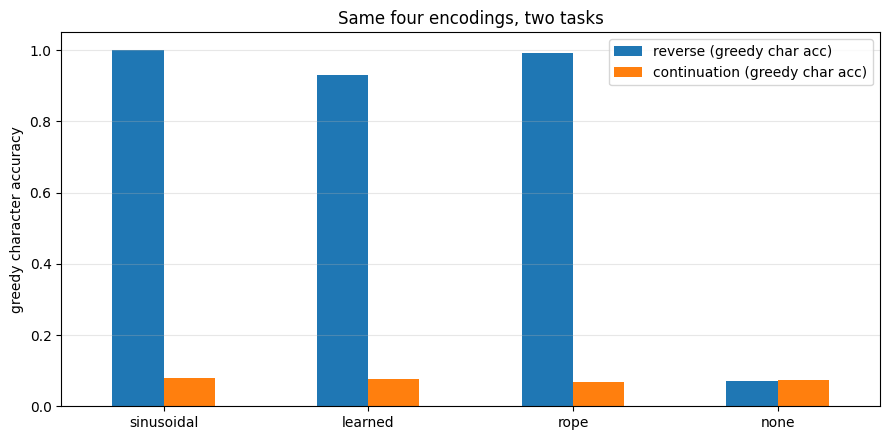

In [11]:
comp = pd.DataFrame({task: {pos: r["greedy"]["char_acc"] for pos, r in results[task].items()} for task in TASKS})
comp.columns = [f"{t} (greedy char acc)" for t in comp.columns]
display(comp.round(4))

ax = comp.plot.bar(figsize=(9, 4.5), rot=0)
ax.set_ylabel("greedy character accuracy"); ax.set_title("Same four encodings, two tasks"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig("task_comparison.png", dpi=150); plt.show()

### Accuracy at each target position (greedy decoding)
Shows *where* in the output each model makes its errors.

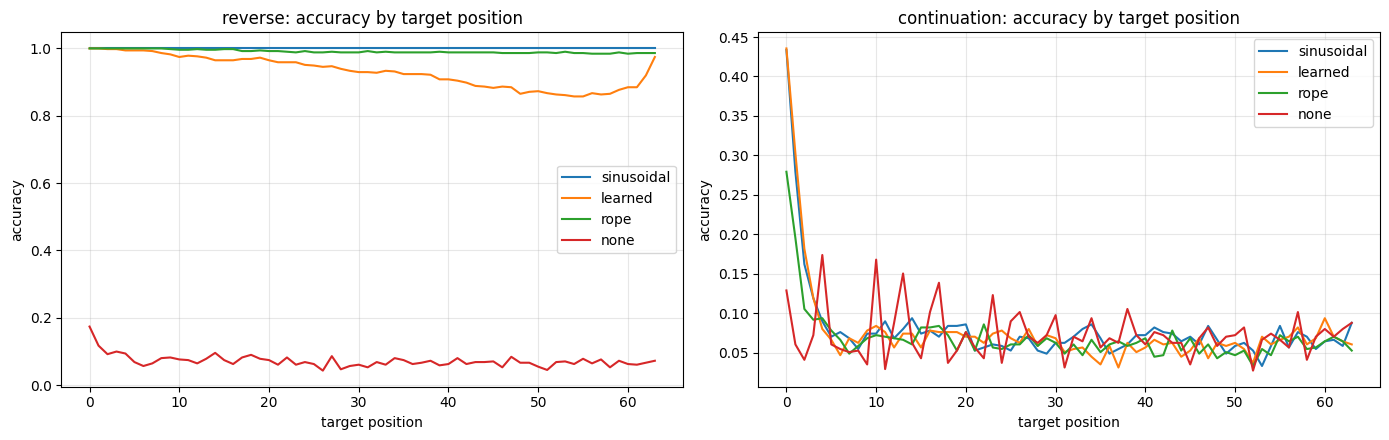

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, task in zip(axes, TASKS):
    for pos, r in results[task].items():
        _, tgt, pred = generate_eval(r["model"], val_data, cfgs[task], n=512)
        ax.plot(per_position_accuracy(pred, tgt).numpy(), label=pos)
    ax.set_title(f"{task}: accuracy by target position"); ax.set_xlabel("target position"); ax.set_ylabel("accuracy")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("per_position.png", dpi=150); plt.show()

Positional information is essential for tasks that depend on exact order: on sequence reversal, the no-position baseline reaches 0% exact match, while sinusoidal, RoPE and learned encodings reach 100%, 98.4% and 76.6%. On text continuation the effect is smaller (perplexity 4.5 for sinusoidal and RoPE, 4.7 for learned, 5.5 without position), since next-character prediction relies mostly on local content. Sinusoidal and RoPE performed equivalently within single-seed noise, and learned converged most slowly. Teacher-forced accuracy overstated the no-position model (60% versus 7% in free-running decoding), so free-running evaluation is needed. Results are from a single seed with default hyperparameters; multiple seeds and a controlled initialization scale are the next steps.

## 10. Length extrapolation
Trained on 64-character sequences; evaluated on 2x and 4x longer ones (teacher forced). `learned` has table rows for those positions, but they were never trained. Treat the `reverse` result with care: reversing a longer sequence is a different mapping that no model was trained on.

In [13]:
for task in TASKS:
    cfg = cfgs[task]
    lengths = [cfg.src_len, cfg.src_len * 2, cfg.src_len * 4]
    loss, acc = {}, {}
    for pos, r in results[task].items():
        ev = [evaluate_at_length(r["model"], val_data, L, cfg) for L in lengths]
        loss[pos], acc[pos] = [e["loss"] for e in ev], [e["acc"] for e in ev]
    cols = [f"{L} tokens" for L in lengths]
    print(f"\n=== {task}: validation loss ===");  display(pd.DataFrame(loss, index=cols).T.round(4))
    print(f"=== {task}: token accuracy ===");       display(pd.DataFrame(acc, index=cols).T.round(4))


=== reverse: validation loss ===


,64 tokens,128 tokens,256 tokens
sinusoidal,0.0000,11.7270,10.3824
learned,0.0206,6.4569,6.6079
rope,0.0008,1.4086,3.1290
none,1.2491,2.2311,3.4622


=== reverse: token accuracy ===


,64 tokens,128 tokens,256 tokens
sinusoidal,1.0000,0.0842,0.1005
learned,0.9938,0.1448,0.1238
rope,0.9997,0.8022,0.5531
none,0.5965,0.4153,0.2542



=== continuation: validation loss ===


,64 tokens,128 tokens,256 tokens
sinusoidal,1.5036,2.6769,3.2086
learned,1.5694,2.5432,3.0386
rope,1.4938,1.8240,2.4152
none,1.7188,1.7918,2.1610


=== continuation: token accuracy ===


,64 tokens,128 tokens,256 tokens
sinusoidal,0.5537,0.3617,0.2662
learned,0.5371,0.3641,0.2777
rope,0.5530,0.4899,0.3782
none,0.4937,0.4743,0.3912


When evaluated on sequences 2× and 4× longer than the 64-token training length, sinusoidal and learned encodings failed on reversal (8 to 14% accuracy at 2× length, with losses above random guessing), while RoPE retained 80% at 2× and 55% at 4×. On continuation, RoPE’s loss increased by 0.92 from 64 to 256 tokens, versus 1.70 for sinusoidal and 1.47 for learned. The no-position model degraded least (+0.44) despite being worst at the training length, showing that in-length quality does not predict length generalization. Overall, RoPE combined top in-length performance with the best robustness among the positional encodings. Results are from one seed and teacher-forced evaluation.

## 11. Conclusions

**Reverse.**
- Without position information the model fails completely: 0% exact match and 7.2% greedy character accuracy. Sinusoidal reaches 100% exact match, RoPE 98.4% and learned 76.6% (after 2500 steps, still improving).
- Sinusoidal converges fastest (96% token accuracy at step 208, versus 57% for RoPE and 36% for learned). RoPE is above 99% by step 416. Learned needs about 2300 steps to reach 99%.
- Teacher-forced accuracy hides the failure of the no-position model (60% teacher-forced versus 7% greedy), so free-running decoding is the reliable measure here.

**Continuation.**
- The encodings separate much less than on reverse. Validation perplexity is 4.52 (sinusoidal), 4.58 (RoPE), 4.73 (learned) and 5.48 (none), so the no-position model is about 21% worse than the best, but it still works.
- Sinusoidal and RoPE are effectively tied (loss differs by 0.011). Greedy accuracy is about 7% for every encoding, so it can't separate them. Perplexity is the right metric for this task.
- Position matters less here, probably because next-character prediction relies mostly on local content (hypothesis, not tested).

**Length extrapolation (trained on 64, tested on 128 and 256).**
- On reverse, sinusoidal and learned collapse at 2× length (8% and 14% accuracy, with losses above random guessing). RoPE keeps 80% at 2× and 55% at 4×.
- On continuation, loss increases from 64 to 256 tokens by +0.92 for RoPE, versus +1.70 for sinusoidal and +1.47 for learned. The no-position model degrades least (+0.44) despite being worst at 64 tokens.
- RoPE is the only encoding that is strong at the training length and reasonably robust beyond it.

**Limits.**
- One seed per run and default hyperparameters, so small gaps (sinusoidal versus RoPE, and probably learned versus sinusoidal) should not be over-interpreted.
- `reverse` is a synthetic task that is easy for the top encodings, and reversing a longer sequence is a different mapping, so its extrapolation result is partly a task-change effect.
- The learned table starts at a smaller scale than the sinusoidal vectors, so its slower convergence may partly come from initialization, and its results beyond 64 positions use untrained rows.

## 12. Download results (Colab)

In [14]:
try:
    from google.colab import files
    for f in ["results_reverse.json", "results_continuation.json", "curves.png",
              "task_comparison.png", "per_position.png"]:
        files.download(f)
except ImportError:
    print("Not running in Colab; files are in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>